# One night, which orbit? A population prior for short arcs

**Science question.** A survey reports four detections of a moving object over half an hour. Every
distance from a few lunar distances to the outer main belt fits those four positions equally well,
so a least-squares fit hands back *an* orbit -- wherever the iterations happened to stop. Can we do
better by asking which of those orbits real objects are actually on?

PyRoOrb does this with a **population prior**: digest2's model of the Solar System population
(the Pan-STARRS Synthetic Solar System Model, Grav et al. 2011) turned into a density over orbits,
including how common a body of the implied absolute magnitude is at each distance. Multiplied
into the *range profile* -- chi² as a function of the line-of-sight distance -- it gives a
posterior over the distance, and a **most probable orbit**.

This notebook shows the prior at work on one main-belt tracklet, then on an NEO it gets wrong,
then **measures** it on two dozen tracklets against JPL's orbits. The rule the measurement
supports, and the one PyRoOrb follows itself: the prior is the right answer to *"what is this
likely to be?"* and the wrong answer to *"is this object unusual?"* -- so it chooses which orbit
to **draw**, and never feeds a hazard, follow-up or identification decision.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
warnings.simplefilter("ignore", pyroorb.UndeterminedOrbitWarning)   # one night never determines an orbit
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## Tracklets and the truth

Two helpers. `first_tracklet` takes the earliest single-station, single-night group of at least four
observations since a date (digest2's own grouping, via `digest2_scores(..., per_tracklet=True)`);
`discovery_tracklet` takes the discovery observation and its station's other detections within
four hours. The truth is JPL Horizons' distance from that station at the first observation.

In [2]:
import json, urllib.parse, urllib.request

def first_tracklet(obs, since="2015-01-01", min_n=4):
    recent = obs.select(start=since, radar=False)
    t0 = min(o["jd_utc"] for o in recent)
    for days in (60, 400, 4000):
        window = recent.select(stop=t0 + days, radar=False)
        for g in pyroorb.digest2_scores(window, per_tracklet=True):
            jd = [window[i]["jd_utc"] for i in g["indices"]]
            if g["n_obs"] >= min_n and max(jd) - min(jd) < 4 / 24:
                return pyroorb.Observations([window[i] for i in g["indices"]], window.meta)
    return None

def discovery_tracklet(obs):
    d = next((o for o in obs if o.get("discovery")), None)
    if d is None:
        raise ValueError("no observation carries the discovery flag")
    return obs.select(d["jd_utc"] - 4 / 24, d["jd_utc"] + 4 / 24, stations=[d["obscode"]],
                      radar=False)

def horizons_distance(desig, jd_utc, site):
    # JPL Horizons: distance (au) of `desig` from MPC station `site` at a UTC Julian date
    cmd = f"'DES={desig};'" if " " in desig else f"'{desig};'"
    q = {"format": "json", "COMMAND": cmd, "EPHEM_TYPE": "OBSERVER", "CENTER": f"'{site}@399'",
         "TLIST": f"'{jd_utc}'", "TLIST_TYPE": "JD", "TIME_TYPE": "UT", "QUANTITIES": "'20'",
         "OBJ_DATA": "NO", "CSV_FORMAT": "YES"}
    res = json.load(urllib.request.urlopen(
        "https://ssd.jpl.nasa.gov/api/horizons.api?" + urllib.parse.urlencode(q), timeout=60))["result"]
    row = res.split("$$SOE")[1].split("$$EOE")[0].strip().splitlines()[0].split(",")
    return float([x for x in row if x.strip()][-2])

## A main-belt tracklet

(300000) is an ordinary main-belt asteroid. Fit its first survey tracklet since 2015 on its own,
as if it were a new object:

In [3]:
obs = pyroorb.fetch_observations("300000")
trk = first_tracklet(obs)
fit = pyroorb.fit_orbit(trk, designation="300000")
first = min(trk, key=lambda o: o["jd_utc"])
truth = horizons_distance("300000", first["jd_utc"], first["obscode"])

span_h = 24 * (max(o["jd_utc"] for o in trk) - first["jd_utc"])
print(f"{len(trk)} observations from station {first['obscode']} over {span_h:.1f} h")
print("determined:", fit.is_determined, "-", fit.determinacy()["headline"])
print(f"least-squares nominal distance: {fit.geocentric_range():.4f} au   (JPL: {truth:.4f} au)")
d2 = pyroorb.digest2_scores(trk)
print("digest2:", {d2["classes"][c]: round(s) for c, s in d2["raw"].items() if c != "Int" and s >= 1})

/Users/petervw/GitHub/fo_clone/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2768: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)


5 observations from station W84 over 0.3 h
determined: False - Essentially unconstrained — 0.0-day, 1-opposition arc
least-squares nominal distance: 0.0183 au   (JPL: 2.4118 au)
digest2: {'NEO(q < 1.3)': 1, 'Inner MB': 3, 'Middle MB': 6, 'Outer MB': 82}


The least-squares solution is a few lunar distances away -- a valid fit to four positions, and
almost certainly wrong. digest2 already says this looks like a main-belt object. Now the range
profile, and the posterior with and without the prior:

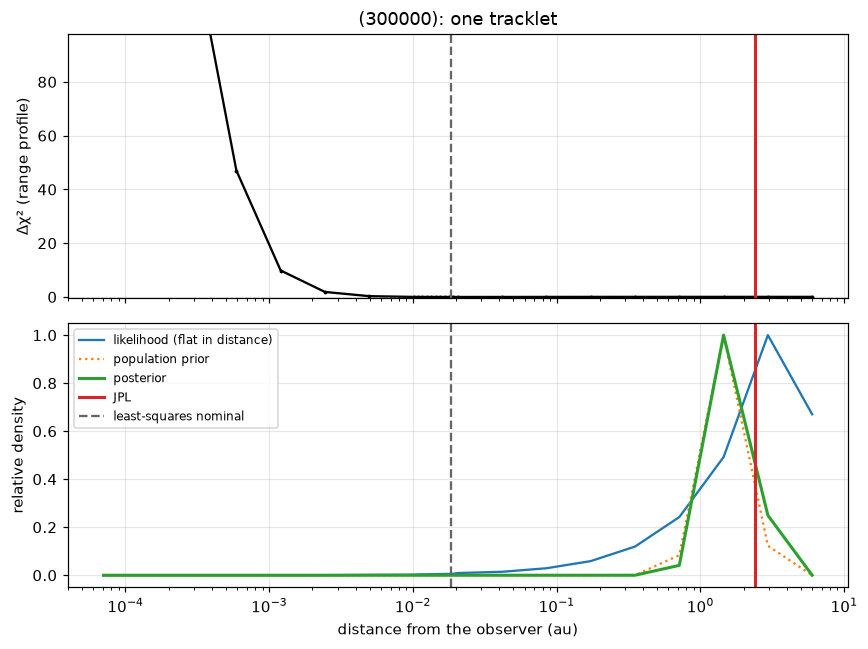

flat       median 2.652 au, 5-95 % 0.266-6.000 au
population median 1.702 au, 5-95 % 0.776-4.423 au


In [4]:
def show(fit, truth, title):
    flat = pyroorb.range_posterior(fit, prior=None)
    pop = pyroorb.range_posterior(fit, prior="population")
    rho = flat["rho_au"]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.semilogx(rho, flat["chi2"] - flat["chi2"].min(), "k.-", ms=3)
    ax1.set_ylabel("Δχ² (range profile)")
    ax1.set_ylim(-0.5, max(10, 1.2 * np.nanpercentile(flat["chi2"] - flat["chi2"].min(), 90)))
    dens = lambda post: post["weight"] / np.gradient(np.log(rho))      # per unit log distance
    ax2.semilogx(rho, dens(flat) / dens(flat).max(), label="likelihood (flat in distance)")
    ax2.semilogx(rho, pop["prior"] / np.nanmax(pop["prior"]), ":", label="population prior")
    ax2.semilogx(rho, dens(pop) / dens(pop).max(), lw=2, label="posterior")
    for ax in (ax1, ax2):
        ax.axvline(truth, color="C3", lw=2, label="JPL" if ax is ax2 else None)
        ax.axvline(fit.geocentric_range(), color="0.4", ls="--",
                   label="least-squares nominal" if ax is ax2 else None)
    ax2.set_xlabel("distance from the observer (au)"); ax2.set_ylabel("relative density")
    ax2.legend(fontsize=8); ax1.set_title(title); plt.tight_layout(); plt.show()
    for name, post in (("flat", flat), ("population", pop)):
        p = post["rho_percentiles"]
        print(f"{name:10s} median {p[50]:.3f} au, 5-95 % {p[5]:.3f}-{p[95]:.3f} au")
    return pop

pop = show(fit, truth, "(300000): one tracklet")

The profile is flat over two orders of magnitude: the positions do not measure the distance.
Read as a likelihood alone ("flat in distance"), the far end wins simply because there is more of
it. The population prior is what pulls the answer into the main belt, and JPL's distance falls
inside its 90 % interval -- while the least-squares nominal sits a hundred times too close.

`most_probable_orbit` turns that into an orbit: the profile's solution at the posterior-median
distance, its radial velocity chosen by the prior too, re-fitted to the observations. It fits the
four positions as well as the least-squares nominal does:

In [5]:
mp = pyroorb.most_probable_orbit(fit)
sbdb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?sstr=300000"))
jpl = {e["name"]: float(e["value"]) for e in sbdb["orbit"]["elements"]}

print(f"{'':24s}{'a (au)':>10s}{'e':>8s}{'i (deg)':>9s}{'rms (arcsec)':>14s}")
for name, f in (("least-squares nominal", fit), ("most probable (prior)", mp)):
    el = f.elements()
    print(f"{name:24s}{el['a']:10.3f}{el['e']:8.3f}{el['i']:9.2f}{f.rms_residual():14.3f}")
print(f"{'JPL (all observations)':24s}{jpl['a']:10.3f}{jpl['e']:8.3f}{jpl['i']:9.2f}")

                            a (au)       e  i (deg)  rms (arcsec)
least-squares nominal        2.010   0.634     0.07         0.036
most probable (prior)        3.124   0.041     0.95         0.049
JPL (all observations)       3.090   0.178     1.40


## An NEO the prior gets wrong

The prior describes the *typical* object with this astrometry. An NEO is, by construction, not
typical. 2023 DZ2, a few tens of metres across, passed inside the Moon's distance a month after its
discovery; on the discovery night it was about 0.1 au away:

12 observations; digest2 NEO score 100 (raw), 100 (no-ID)


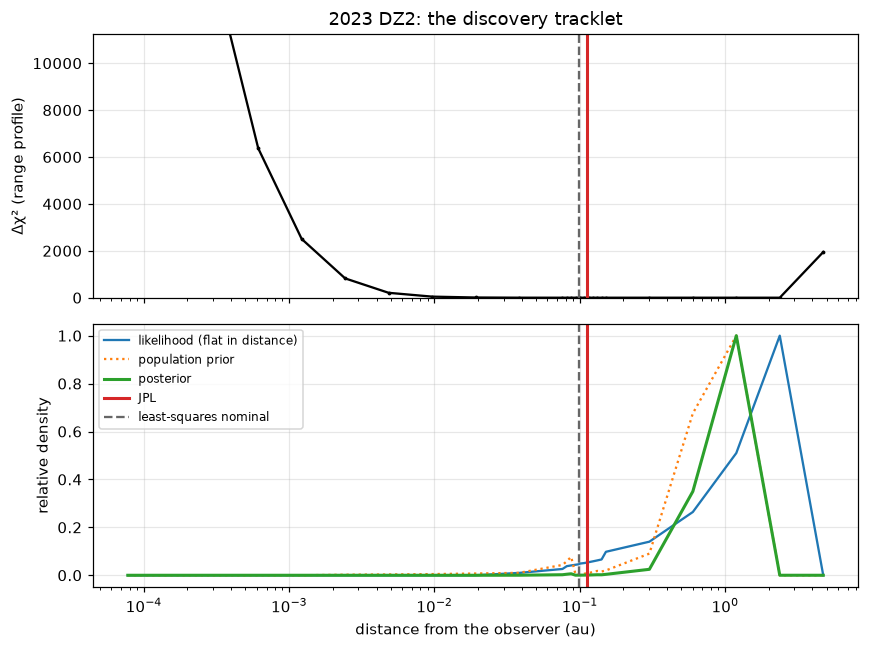

flat       median 1.566 au, 5-95 % 0.158-4.260 au
population median 1.029 au, 5-95 % 0.383-2.218 au


In [6]:
neo = pyroorb.fetch_observations("2023 DZ2")
trk_neo = discovery_tracklet(neo)
fit_neo = pyroorb.fit_orbit(trk_neo, designation="2023 DZ2")
first = min(trk_neo, key=lambda o: o["jd_utc"])
truth_neo = horizons_distance("2023 DZ2", first["jd_utc"], first["obscode"])
d2 = pyroorb.digest2_scores(trk_neo)
print(f"{len(trk_neo)} observations; digest2 NEO score {d2['raw']['NEO']:.0f} (raw), "
      f"{d2['noid']['NEO']:.0f} (no-ID)")
show(fit_neo, truth_neo, "2023 DZ2: the discovery tracklet");

An object whose motion also fits the main belt is, in the population, most likely a larger and
more distant one, so the prior moves this one out by about a factor of ten -- with the truth
below its 90 % interval. The least-squares fit, for once, was close. digest2, which rests on the
same population model, still scores it as an NEO, because it asks what share of the fitting
orbits are NEOs, not which single one is most typical. That is why PyRoOrb never lets the prior
decide a hazard or follow-up question.

## Measured: two dozen tracklets

Twelve numbered main-belt asteroids (their first survey tracklet since 2015) and fourteen NEOs (their
discovery tracklets, six of them imminent impactors). For each, the distance from the least-squares
fit, from the likelihood alone, and from the population posterior, against JPL:

In [7]:
import pandas as pd

MBA = ["100000", "150000", "200000", "250000", "300000", "350000", "400000", "450000",
       "500000", "550000", "600000", "650000"]
NEO = ["2024 MK", "2023 DZ2", "2024 PT5", "2023 BU", "2024 YR4", "2022 AP7", "2019 OK",
       "2020 XL5", "2008 TC3", "2018 LA", "2022 EB5", "2023 CX1", "2024 BX1", "2024 RW1"]

rows = []
for kind, names in (("main belt", MBA), ("NEO", NEO)):
    for desig in names:
        try:
            o = pyroorb.fetch_observations(desig)
            t = first_tracklet(o) if kind == "main belt" else discovery_tracklet(o)
            f = pyroorb.fit_orbit(t, designation=desig)
            flat, pop = pyroorb.range_posterior(f, prior=None), pyroorb.range_posterior(f)
            first = min(t, key=lambda x: x["jd_utc"])
            truth = horizons_distance(desig, first["jd_utc"], first["obscode"])
        except Exception as ex:                       # a fetch or Horizons hiccup: say so, go on
            print(f"{desig}: skipped ({type(ex).__name__}: {str(ex)[:80]})")
            continue
        rows.append({"kind": kind, "object": desig, "n": len(t), "V": pop["vmag"],
                     "JPL": truth, "least squares": f.geocentric_range(),
                     "flat": flat["rho_percentiles"][50], "population": pop["rho_percentiles"][50],
                     "flat in 90%": flat["rho_percentiles"][5] <= truth <= flat["rho_percentiles"][95],
                     "prior in 90%": pop["rho_percentiles"][5] <= truth <= pop["rho_percentiles"][95]})
table = pd.DataFrame(rows)
table.round(4)

/Users/petervw/GitHub/fo_clone/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2768: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)


2018 LA: skipped (ValueError: no observation carries the discovery flag)
2022 EB5: skipped (ValueError: no observation carries the discovery flag)


,kind,object,n,V,JPL,least squares,flat,population,flat in 90%,prior in 90%
0,main belt,100000,4,19.1750,1.0319,0.0194,2.6874,2.3033,True,True
1,main belt,150000,4,19.7100,2.2381,7.8500,3.2760,1.7475,True,True
2,main belt,200000,4,20.3750,2.3195,6.2670,3.3203,1.8522,True,True
3,main belt,250000,4,19.1000,1.5795,0.0125,2.0289,1.4351,True,True
4,main belt,300000,5,22.0000,2.4118,0.0183,2.6516,1.7017,True,True
5,main belt,350000,4,20.6400,1.7435,0.5988,2.6485,1.4307,True,True
6,main belt,400000,4,21.2100,1.3842,0.4749,2.6641,1.4516,True,True
7,main belt,450000,4,20.9300,1.0758,0.2028,3.2252,1.5304,True,True
8,main belt,500000,4,20.4400,2.1980,3.9580,3.2427,1.6145,True,True
9,main belt,550000,4,21.2350,1.8898,0.5798,1.6951,1.9381,True,True


median |log10(estimate / JPL)| -- 0.1 is 26 %, 0.3 a factor of two, 1 a factor of ten
           least squares  flat  population   n  flat 90% covers  prior 90% covers
kind                                                                             
NEO                 0.08  0.16        0.18  12             0.67              0.33
main belt           0.63  0.17        0.10  12             1.00              1.00


/tmp/ipykernel_920562/1088447178.py:14: UserWarning: You passed an edgecolor/edgecolors ('C0') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(table.loc[sel, "JPL"], table.loc[sel, name] / table.loc[sel, "JPL"], marker=m,
/tmp/ipykernel_920562/1088447178.py:14: UserWarning: You passed an edgecolor/edgecolors ('C3') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(table.loc[sel, "JPL"], table.loc[sel, name] / table.loc[sel, "JPL"], marker=m,


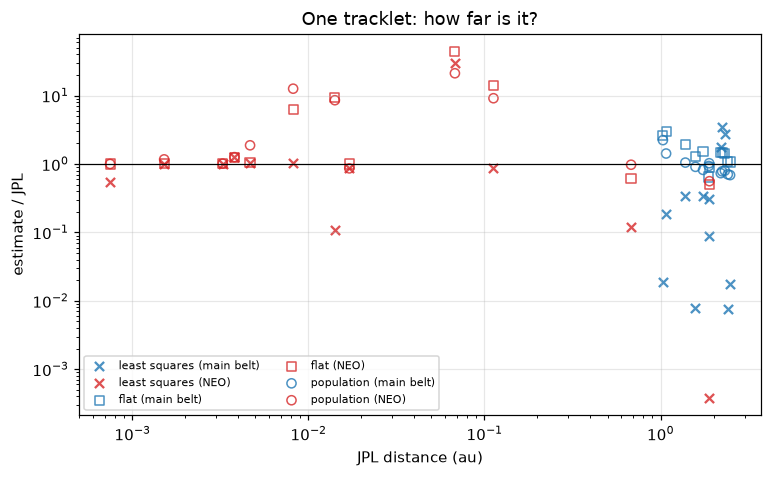

In [8]:
est = ["least squares", "flat", "population"]
err = table[est].div(table["JPL"], axis=0).apply(np.log10).abs()
summary = err.groupby(table["kind"]).median().round(2)
summary["n"] = table.groupby("kind").size()
summary["flat 90% covers"] = table.groupby("kind")["flat in 90%"].mean().round(2)
summary["prior 90% covers"] = table.groupby("kind")["prior in 90%"].mean().round(2)
print("median |log10(estimate / JPL)| -- 0.1 is 26 %, 0.3 a factor of two, 1 a factor of ten")
print(summary.to_string())

fig, ax = plt.subplots()
for k, (name, m) in enumerate(zip(est, ("x", "s", "o"))):
    for kind, c in (("main belt", "C0"), ("NEO", "C3")):
        sel = table["kind"] == kind
        ax.scatter(table.loc[sel, "JPL"], table.loc[sel, name] / table.loc[sel, "JPL"], marker=m,
                   facecolors="none" if m != "x" else c, edgecolors=c, color=c,
                   label=f"{name} ({kind})", alpha=0.8)
ax.set(xscale="log", yscale="log", xlabel="JPL distance (au)", ylabel="estimate / JPL",
       title="One tracklet: how far is it?")
ax.axhline(1, color="k", lw=0.8); ax.legend(fontsize=7, ncol=2); plt.show()

## What the measurement says

* **For the population the prior was built from, it works.** On the main-belt tracklets the
  posterior median is typically within ~25 % of the truth, against a factor of four for the
  least-squares nominal (which can sit anywhere along the valley, often lunar distances away) and
  ~50 % for the likelihood alone, which drifts to the far end of the scan. Its 90 % interval
  contained the truth every time.
* **For an NEO the prior is the wrong question.** Where one night does pin the distance -- the
  imminent impactors, close enough for the observer's motion to give a parallax -- all three
  estimates agree and the prior does no harm. Where it does not, the prior files the object
  with the main belt it resembles: its interval missed the truth for most of these NEOs, and the
  least-squares nominal was the best of the three.
* digest2's class scores, computed from the same population, remain the triage signal for an NEO:
  they ask what *share* of the fitting orbits are NEOs, not which one is most typical.

So PyRoOrb's rule: `most_probable_orbit` is what to *draw* when someone asks to see an orbit for a
tracklet, and `range_posterior` what to *say* about its likely distance -- labelled as a population
statement. Hazard (MOID, impact), follow-up, identification and NEOCP questions use the
likelihood-only family (`fit.determinacy()`, `sample_orbits(fit, method="sr")`) and digest2.